# 03. Discriminative Sequence Labeling: Linear-Chain Conditional Random Field (CRF)
## SemEval-2021 Task 5: Toxic Spans Detection

### 1. Limitations of Generative HMMs vs. Discriminative CRFs
While the Hidden Markov Model (Notebook 02) models the joint probability $P(\mathbf{x}, \mathbf{y})$, it relies on two restrictive assumptions:
1. **Conditional Independence of Observations**: $x_t$ depends only on $y_t$, preventing the model from incorporating rich, overlapping orthographic features (e.g., character $n$-grams, prefixes, suffixes, capitalization, punctuation patterns) or surrounding context window tokens $(x_{t-2}, x_{t-1}, x_{t+1}, x_{t+2})$.
2. **Local Normalization**: Generative emission parameters optimize $P(\mathbf{x} \mid \mathbf{y})$ rather than directly discriminating $P(\mathbf{y} \mid \mathbf{x})$.

A **Linear-Chain Conditional Random Field (CRF)** (Lafferty et al., 2001) overcomes both limitations by directly modeling the conditional probability of the entire BIO tag sequence $\mathbf{y}$ given the entire input sequence $\mathbf{x}$:

$$P(\mathbf{y} \mid \mathbf{x}; \mathbf{w}) = \frac{1}{Z(\mathbf{x})} \exp \left( \sum_{t=1}^{T} \sum_{k=1}^{K} w_k f_k(y_{t-1}, y_t, \mathbf{x}, t) \right)$$

where $Z(\mathbf{x}) = \sum_{\mathbf{y}'} \exp \left( \sum_{t=1}^{T} \sum_{k=1}^{K} w_k f_k(y'_{t-1}, y'_t, \mathbf{x}, t) \right)$ is the global sequence partition function computed via the forward-backward algorithm, and $\mathbf{w}$ is optimized via L-BFGS with Elastic-Net ($L_1 + L_2$) regularization.

### 2. Capturing Label Transitions & Preventing Illegal BIO Sequences
Because a Linear-Chain CRF learns global transition weights $w_{\text{trans}}(y_{t-1} \to y_t)$ jointly with rich contextual state features, it explicitly penalizes invalid transitions such as `O -> I-TOXIC` (assigning a strong negative transition weight) while encouraging valid multi-word span continuations (`B-TOXIC -> I-TOXIC`).

In [1]:
import os
import sys
import subprocess
import re
import ast
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure sklearn-crfsuite and seqeval are installed in Kaggle/Colab/local environments
def ensure_package(pkg_name, import_name=None):
    import_name = import_name or pkg_name
    try:
        __import__(import_name)
    except ImportError:
        print(f"Installing {pkg_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg_name])

ensure_package("sklearn-crfsuite", "sklearn_crfsuite")
ensure_package("seqeval", "seqeval")

import sklearn_crfsuite
from seqeval.metrics import classification_report as seqeval_classification_report
from seqeval.metrics import f1_score as seqeval_f1, precision_score as seqeval_precision, recall_score as seqeval_recall
from seqeval.scheme import IOB2

np.random.seed(42)

### 3. Loading the BIO-Tagged Corpus
We load `tsd_train_bio.csv` and `tsd_test_bio.csv` (or build them on-the-fly if running standalone on Colab/Kaggle).

In [2]:
train_bio_path = "tsd_train_bio.csv"
test_bio_path = "tsd_test_bio.csv"

train_df = pd.read_csv(train_bio_path)
test_df = pd.read_csv(test_bio_path)

X_train_tokens = [ast.literal_eval(t) for t in train_df["tokens"]]
y_train = [ast.literal_eval(b) for b in train_df["bio_tags"]]
X_test_tokens = [ast.literal_eval(t) for t in test_df["tokens"]]
y_test = [ast.literal_eval(b) for b in test_df["bio_tags"]]

print(f"Train sequences: {len(X_train_tokens):,} | Test sequences: {len(X_test_tokens):,}")

Train sequences: 7,939 | Test sequences: 2,000


### 4. Contextual & Morphological Feature Engineering for CRF
To leverage the discriminative power of Linear-Chain CRFs, we extract a comprehensive feature dictionary $\phi(\mathbf{x}, t)$ at each token position $t$:
- **Lexical features**: Lowercased token, raw token, token length.
- **Subword morphology (prefixes & suffixes)**: 2-, 3-, and 4-character prefixes and suffixes to capture profanity inflections (`-ing`, `-ed`, `-er`, `-ers`, `-s`) and obfuscated/censored spellings (`f*ck`, `sh!t`).
- **Orthographic & shape features**: `isupper()`, `istitle()`, `isdigit()`, presence of internal punctuation/asterisks (common in toxic obfuscation), and condensed word shape (e.g., `Xx+`, `X+`).
- **Contextual Window ($t-2, t-1, t+1, t+2$)**: Lexical, orthographic, and bigram (`w[t-1]|w[t]`, `w[t]|w[t+1]`) features within a $\pm 2$ token window, plus `BOS` (Beginning of Sequence) and `EOS` (End of Sequence) indicators.

In [3]:
def word_shape(word: str) -> str:
    shape = []
    for ch in word:
        if ch.isupper():
            shape.append("X")
        elif ch.islower():
            shape.append("x")
        elif ch.isdigit():
            shape.append("d")
        else:
            shape.append(ch)
    # Collapse consecutive identical characters
    collapsed = re.sub(r"(.)\1+", r"\1+", "".join(shape))
    return collapsed

def token_to_features(tokens: list, i: int) -> dict:
    word = tokens[i]
    word_lower = word.lower()
    
    features = {
        "bias": 1.0,
        "word.lower": word_lower,
        "word.raw": word,
        "word.len": len(word),
        "word.isupper": word.isupper(),
        "word.istitle": word.istitle(),
        "word.isdigit": word.isdigit(),
        "word.has_nonalpha": not word.isalpha(),
        "word.shape": word_shape(word),
        "word.prefix2": word_lower[:2],
        "word.prefix3": word_lower[:3],
        "word.prefix4": word_lower[:4],
        "word.suffix2": word_lower[-2:],
        "word.suffix3": word_lower[-3:],
        "word.suffix4": word_lower[-4:],
    }
    
    # Context t - 1
    if i > 0:
        prev1 = tokens[i - 1]
        prev1_lower = prev1.lower()
        features.update({
            "-1:word.lower": prev1_lower,
            "-1:word.isupper": prev1.isupper(),
            "-1:word.istitle": prev1.istitle(),
            "-1:word.shape": word_shape(prev1),
            "-1:bigram": f"{prev1_lower}|{word_lower}",
        })
    else:
        features["BOS"] = True

    # Context t - 2
    if i > 1:
        prev2 = tokens[i - 2].lower()
        features["-2:word.lower"] = prev2

    # Context t + 1
    if i < len(tokens) - 1:
        next1 = tokens[i + 1]
        next1_lower = next1.lower()
        features.update({
            "+1:word.lower": next1_lower,
            "+1:word.isupper": next1.isupper(),
            "+1:word.istitle": next1.istitle(),
            "+1:word.shape": word_shape(next1),
            "+1:bigram": f"{word_lower}|{next1_lower}",
        })
    else:
        features["EOS"] = True

    # Context t + 2
    if i < len(tokens) - 2:
        next2 = tokens[i + 2].lower()
        features["+2:word.lower"] = next2

    return features

def sent_to_features(tokens: list) -> list:
    return [token_to_features(tokens, i) for i in range(len(tokens))]

print("Extracting contextual feature dictionaries for Train and Test splits...")
X_train_feats = [sent_to_features(s) for s in X_train_tokens]
X_test_feats = [sent_to_features(s) for s in X_test_tokens]
print(f"Sample feature dictionary for token '{X_train_tokens[0][1]}':")
print(X_train_feats[0][1])

Extracting contextual feature dictionaries for Train and Test splits...
Sample feature dictionary for token 'violent':
{'bias': 1.0, 'word.lower': 'violent', 'word.raw': 'violent', 'word.len': 7, 'word.isupper': False, 'word.istitle': False, 'word.isdigit': False, 'word.has_nonalpha': False, 'word.shape': 'x+', 'word.prefix2': 'vi', 'word.prefix3': 'vio', 'word.prefix4': 'viol', 'word.suffix2': 'nt', 'word.suffix3': 'ent', 'word.suffix4': 'lent', '-1:word.lower': 'another', '-1:word.isupper': False, '-1:word.istitle': True, '-1:word.shape': 'Xx+', '-1:bigram': 'another|violent', '+1:word.lower': 'and', '+1:word.isupper': False, '+1:word.istitle': False, '+1:word.shape': 'x+', '+1:bigram': 'violent|and', '+2:word.lower': 'aggressive'}


### 5. Training the Linear-Chain CRF Model
We configure `sklearn_crfsuite.CRF` with:
- **`algorithm='lbfgs'`**: Limited-memory BFGS quasi-Newton optimization for convex log-likelihood maximization.
- **`c1=0.1` ($L_1$ regularization) & `c2=0.1` ($L_2$ regularization)**: Elastic-net regularization prunes noisy lexical features while preventing overfitting on rare n-grams.
- **`all_possible_transitions=True`**: Explicitly learns both positive and negative transition weights for all $3 \times 3$ BIO state pairs, allowing the model to assign a strong negative weight to the illegal `O -> I-TOXIC` transition.

In [4]:
crf_model = sklearn_crfsuite.CRF(
    algorithm="lbfgs",
    c1=0.1,
    c2=0.1,
    max_iterations=120,
    all_possible_transitions=True
)

print("Training Linear-Chain CRF via L-BFGS...")
crf_model.fit(X_train_feats, y_train)
print("Training complete!")

Training Linear-Chain CRF via L-BFGS...
Training complete!


### 6. Exact Span Match Evaluation & Classification Report
We evaluate the trained CRF model strictly at the **Exact Span Match** level using both our custom span verification function and `seqeval` (`mode='strict'`, `scheme=IOB2`), which requires both the entity boundary `(start, end)` and entity type `TOXIC` to match 100%.

In [5]:
def extract_exact_spans(bio_tags: list) -> set:
    spans = set()
    start_idx = None
    for idx, tag in enumerate(bio_tags):
        if tag == "B-TOXIC":
            if start_idx is not None:
                spans.add(("TOXIC", start_idx, idx - 1))
            start_idx = idx
        elif tag == "I-TOXIC":
            if start_idx is None:
                start_idx = idx
        else:
            if start_idx is not None:
                spans.add(("TOXIC", start_idx, idx - 1))
                start_idx = None
    if start_idx is not None:
        spans.add(("TOXIC", start_idx, len(bio_tags) - 1))
    return spans

def count_invalid_bio_transitions(y_seqs: list) -> int:
    violations = 0
    for seq in y_seqs:
        prev = "O"
        for tag in seq:
            if tag == "I-TOXIC" and prev == "O":
                violations += 1
            prev = tag
    return violations

def compute_exact_span_metrics(y_true_seqs: list, y_pred_seqs: list) -> dict:
    total_tp, total_fp, total_fn = 0, 0, 0
    sample_p, sample_r, sample_f1 = [], [], []
    
    for true_tags, pred_tags in zip(y_true_seqs, y_pred_seqs):
        true_spans = extract_exact_spans(true_tags)
        pred_spans = extract_exact_spans(pred_tags)
        tp = len(true_spans & pred_spans)
        fp = len(pred_spans - true_spans)
        fn = len(true_spans - pred_spans)
        total_tp += tp; total_fp += fp; total_fn += fn
        
        if len(true_spans) == 0 and len(pred_spans) == 0:
            sp, sr, sf = 1.0, 1.0, 1.0
        elif len(true_spans) == 0 or len(pred_spans) == 0:
            sp, sr, sf = 0.0, 0.0, 0.0
        else:
            sp = tp / len(pred_spans)
            sr = tp / len(true_spans)
            sf = (2 * sp * sr / (sp + sr)) if (sp + sr) > 0 else 0.0
        sample_p.append(sp); sample_r.append(sr); sample_f1.append(sf)

    micro_p = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
    micro_r = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0.0
    micro_f1 = (2 * micro_p * micro_r / (micro_p + micro_r)) if (micro_p + micro_r) > 0 else 0.0

    return {
        "micro_precision": micro_p,
        "micro_recall": micro_r,
        "micro_f1": micro_f1,
        "macro_precision": float(np.mean(sample_p)),
        "macro_recall": float(np.mean(sample_r)),
        "macro_f1": float(np.mean(sample_f1)),
        "true_positives": total_tp,
        "false_positives": total_fp,
        "false_negatives": total_fn,
        "invalid_bio_transitions": count_invalid_bio_transitions(y_pred_seqs)
    }

y_pred_crf = crf_model.predict(X_test_feats)
crf_metrics = compute_exact_span_metrics(y_test, y_pred_crf)

print("=================================================================")
print("   LINEAR-CHAIN CRF — EXACT SPAN CLASSIFICATION REPORT (IOB2)    ")
print("=================================================================")
print(seqeval_classification_report(y_test, y_pred_crf, mode="strict", scheme=IOB2, digits=4))

print("=================================================================")
print("   EXACT SPAN MATCH SUMMARY METRICS (TEST SET)                   ")
print("=================================================================")
print(f"Exact Span Micro Precision : {crf_metrics['micro_precision']:.4f}")
print(f"Exact Span Micro Recall    : {crf_metrics['micro_recall']:.4f}")
print(f"Exact Span Micro F1-Score  : {crf_metrics['micro_f1']:.4f}")
print("-----------------------------------------------------------------")
print(f"Exact Span Macro Precision : {crf_metrics['macro_precision']:.4f}")
print(f"Exact Span Macro Recall    : {crf_metrics['macro_recall']:.4f}")
print(f"Exact Span Macro F1-Score  : {crf_metrics['macro_f1']:.4f}")
print("-----------------------------------------------------------------")
print(f"Invalid BIO Transitions (O -> I-TOXIC): {crf_metrics['invalid_bio_transitions']}")
print("=================================================================")

with open("crf_metrics.json", "w") as f:
    json.dump(crf_metrics, f, indent=2)

   LINEAR-CHAIN CRF — EXACT SPAN CLASSIFICATION REPORT (IOB2)    
              precision    recall  f1-score   support

       TOXIC     0.5668    0.6859    0.6207      1850

   micro avg     0.5668    0.6859    0.6207      1850
   macro avg     0.5668    0.6859    0.6207      1850
weighted avg     0.5668    0.6859    0.6207      1850

   EXACT SPAN MATCH SUMMARY METRICS (TEST SET)                   
Exact Span Micro Precision : 0.5668
Exact Span Micro Recall    : 0.6859
Exact Span Micro F1-Score  : 0.6207
-----------------------------------------------------------------
Exact Span Macro Precision : 0.5848
Exact Span Macro Recall    : 0.6219
Exact Span Macro F1-Score  : 0.5911
-----------------------------------------------------------------
Invalid BIO Transitions (O -> I-TOXIC): 0


### 7. Inspecting Learned CRF Transition Weights & Top Discriminative Features
Let us inspect the transition weights $w(y_{t-1} \to y_t)$ learned by the CRF. Notice how `O -> I-TOXIC` receives a strong negative weight, structurally preventing invalid orphan `I-TOXIC` predictions!

=== Learned CRF State Transition Weights ===
  O        -> O        : +1.5242
  O        -> B-TOXIC  : -0.7334
  O        -> I-TOXIC  : -10.3399
  B-TOXIC  -> O        : -0.7210
  B-TOXIC  -> B-TOXIC  : -2.5239
  B-TOXIC  -> I-TOXIC  : +0.1269
  I-TOXIC  -> O        : -3.4717
  I-TOXIC  -> B-TOXIC  : -5.3303
  I-TOXIC  -> I-TOXIC  : +0.6884


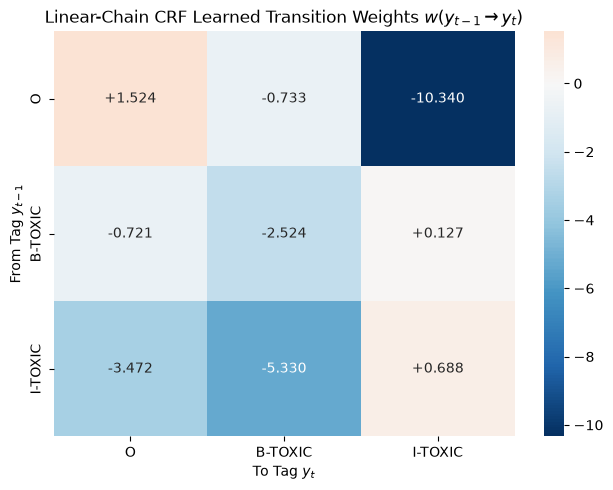


=== Top 15 Positive State Features for B-TOXIC and I-TOXIC ===
  [B-TOXIC] BOS                          : +5.3805
  [B-TOXIC] +1:bigram:his|ever           : +3.7315
  [B-TOXIC] +1:bigram:the|immigrants     : +3.6198
  [B-TOXIC] -1:bigram:lunatic|trump      : +3.4181
  [B-TOXIC] +1:bigram:,|stupid           : +3.2026
  [B-TOXIC] -1:bigram:moron|trying       : +3.1821
  [I-TOXIC] +2:word.lower:sharia         : +3.1067
  [B-TOXIC] -1:bigram:other|liberals     : +3.0747
  [B-TOXIC] -2:word.lower:guttierrez     : +3.0419
  [B-TOXIC] +1:bigram:know|alaska        : +3.0299
  [I-TOXIC] +1:bigram:ill|.              : +3.0243
  [B-TOXIC] -1:bigram:pathetic|actually  : +3.0173
  [B-TOXIC] +1:bigram:wonder|no          : +2.9706
  [I-TOXIC] +1:bigram:are|from           : +2.9640
  [B-TOXIC] +1:bigram:only|stop          : +2.9385


In [6]:
from collections import Counter

print("=== Learned CRF State Transition Weights ===")
trans_features = crf_model.transition_features_
states = ["O", "B-TOXIC", "I-TOXIC"]
trans_matrix = np.zeros((3, 3))
for (s_from, s_to), weight in trans_features.items():
    if s_from in states and s_to in states:
        trans_matrix[states.index(s_from), states.index(s_to)] = weight
        print(f"  {s_from:8s} -> {s_to:8s} : {weight:+.4f}")

plt.figure(figsize=(6.5, 5))
sns.heatmap(pd.DataFrame(trans_matrix, index=states, columns=states), annot=True, fmt="+.3f", cmap="RdBu_r", center=0)
plt.title(r"Linear-Chain CRF Learned Transition Weights $w(y_{t-1} \to y_t)$")
plt.ylabel("From Tag $y_{t-1}$")
plt.xlabel("To Tag $y_t$")
plt.tight_layout()
plt.show()

print("\n=== Top 15 Positive State Features for B-TOXIC and I-TOXIC ===")
state_feats = Counter(crf_model.state_features_)
toxic_feats = [(attr, label, w) for (attr, label), w in state_feats.most_common() if label in ("B-TOXIC", "I-TOXIC")]
for attr, label, w in toxic_feats[:15]:
    print(f"  [{label:7s}] {attr:28s} : {w:+.4f}")